In [361]:
from scipy.ndimage import label
import SimpleITK as sitk
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.filters import frangi
from scipy.ndimage import grey_dilation, grey_erosion
from scipy.ndimage import gaussian_filter, grey_opening

nifti_dir = r'Dataset\NIFTIs\HGUCEGXI.nii'
sitk_image = sitk.ReadImage(nifti_dir)

In [362]:
def get_region_grown(sitk_image, seed, r, dilation_steps=0):
    seed_value = np.mean([
        sitk.GetArrayFromImage(sitk_image)[seed[0] + i[0], seed[1] + i[1], seed[2] + i[2]]
        for i in [[0, 0, 0], [0, 0, 1], [0, 1, 0], [0, 1, 1], [1, 0, 0], [1, 0, 1], [1, 1, 0], [1, 1, 1]]
    ])

    seg_con = sitk.ConnectedThreshold(sitk_image, seedList=[seed], lower=seed_value - r, upper=seed_value + r)
    temp = sitk.GetArrayFromImage(seg_con)

    if dilation_steps != 0:
        temp = cv2.dilate(
            temp.astype(np.uint8),
            np.array([[0, 1, 0], [1, 1, 1], [0, 1, 0]]).astype(np.uint8),
            iterations=dilation_steps)

    return temp


def fill_small_holes(mask, max_size):
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(1 - mask.astype(np.uint8))

    for i in range(1, num_labels):
        if stats[i, cv2.CC_STAT_AREA] < max_size:
            mask[labels == i] = 1

    return mask


def segment_fat(sitk_image, seed, a_b_range=[-165, -65]):
    # The first region growing for segmenting the fat and around.
    fat_and_around = get_region_grown(sitk_image, seed, 15, 3)
    temp = sitk.GetArrayFromImage(sitk_image)
    # The second region growing for segmenting the fat and the organs (This time only with thresholding).
    fat_and_organs = (temp > a_b_range[0]) & (temp < a_b_range[1])

    fat_and_organs = [fill_small_holes(s, 10) for s in fat_and_organs]
    fat_and_organs = np.array(fat_and_organs)
    fat_and_organs = [fill_small_holes(s, 10) for s in fat_and_organs.transpose(1, 2, 0)]
    fat_and_organs = np.array(fat_and_organs).transpose(2, 0, 1)
    fat_and_organs = [fill_small_holes(s, 10) for s in fat_and_organs.transpose(2, 0, 1)]
    fat_and_organs = np.array(fat_and_organs).transpose(1, 2, 0)

    # Combine the two masks.
    fat = fat_and_organs * fat_and_around

    fat = sitk.ConnectedThreshold(sitk.GetImageFromArray(fat * 100), seedList=[seed], lower=90, upper=110)
    fat = sitk.GetArrayFromImage(fat)

    # Fill the small areas around and in between.
    fat = [fill_small_holes(s, 40) for s in fat]
    fat = np.array(fat)

    return fat

In [363]:
HP = {
    "slice_range": [199, 230],  ## slice range fo the umbilical region
    "vertical_slice_range": [100, 200],  ## slice range fo the umbilical region

    "slice_no": np.array([10, 11, 12, 13, 18, 19, 20, 21])+1,  ## slice to visualize

    "frangi_scale_range": (1, 2),
    "frangi_scale_step": 0.2,
    "frangi_beta": 1,
    "frangi_gamma": 4,

    "vessel_size_threshold": 10000,  # Minimum number of pixels for a region to be kept
    "vertical_vessel_size_threshold": 50
}

In [374]:
img = sitk.GetArrayFromImage(sitk_image)
seed = (215, 120, 300)

fat_seg2 = segment_fat(sitk_image, seed, a_b_range=[-165, -65])
img = (img + 10000) * fat_seg2 - 10000

In [375]:
max_value, min_value, upper_gap_value, lower_gap_value = 97, 60, 2, 15
temp = [slice(*HP["slice_range"]), slice(*HP["vertical_slice_range"])]
upper_gap_value, lower_gap_value = max_value + upper_gap_value, min_value - lower_gap_value
max_value, min_value, upper_gap_value, lower_gap_value = (
    np.percentile(img[*temp][fat_seg2[*temp].astype(bool)], [max_value, min_value, upper_gap_value, lower_gap_value]))
img[img < min_value] = lower_gap_value
img[img > max_value] = upper_gap_value

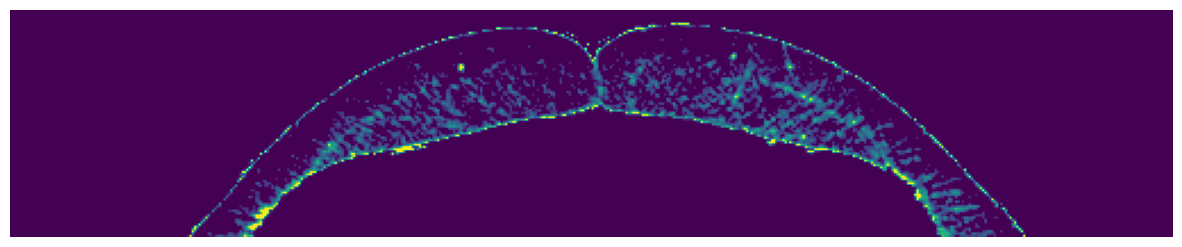

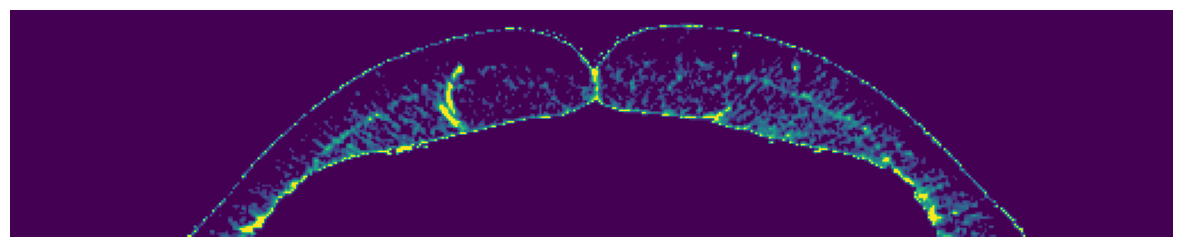

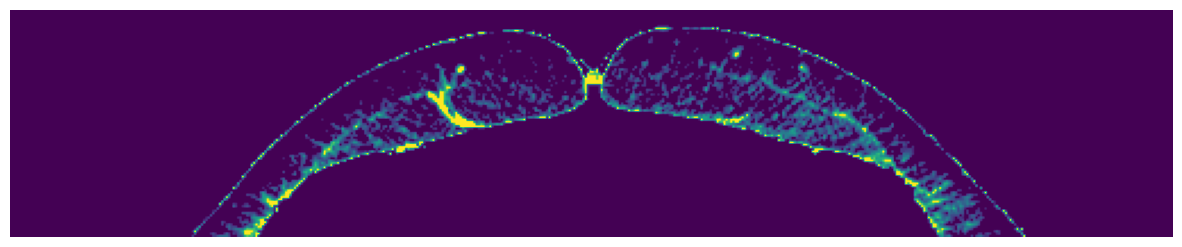

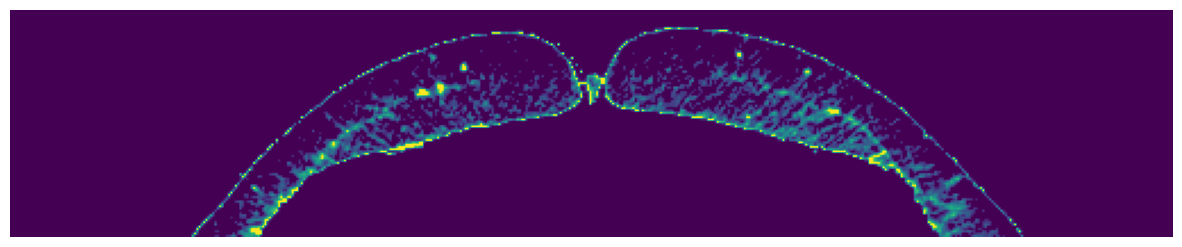

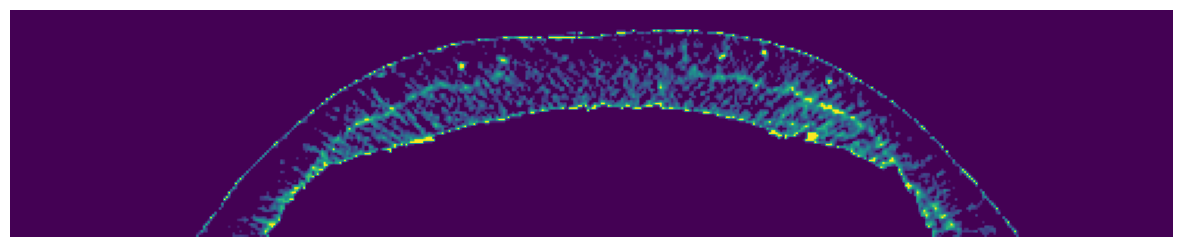

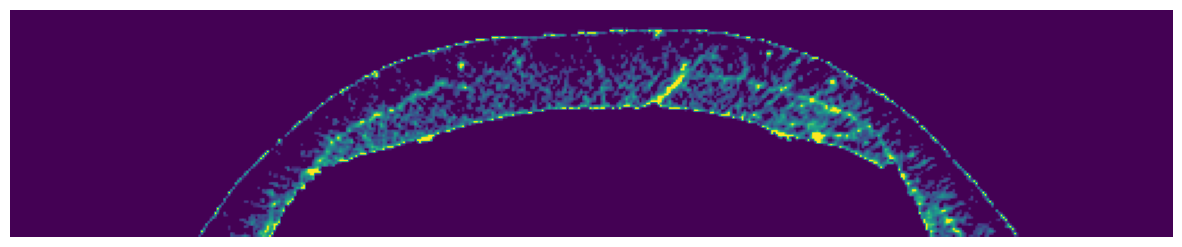

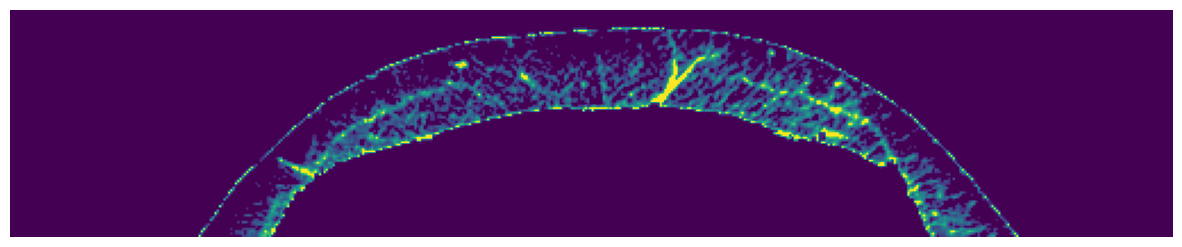

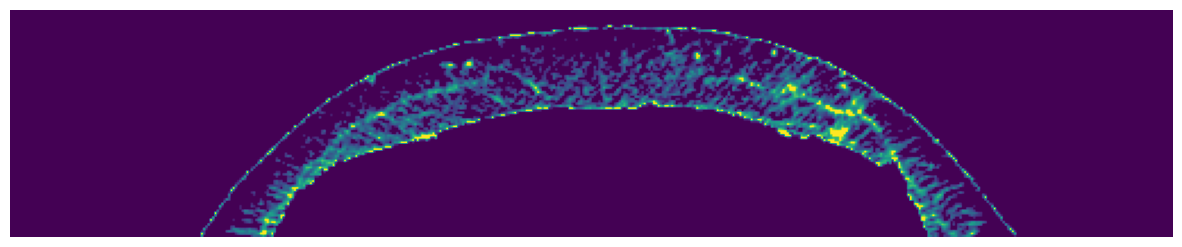

In [376]:
cropped_image = img[*temp].copy()
cropped_image = gaussian_filter(cropped_image, sigma=0.4)
cropped_image[cropped_image < min_value] = lower_gap_value
cropped_image[cropped_image > max_value] = upper_gap_value
cropped_image = (cropped_image - lower_gap_value) / (upper_gap_value - lower_gap_value)

for i in HP["slice_no"]:
    plt.figure(figsize=(15, 10), dpi=100)
    plt.imshow(cropped_image[i])
    plt.axis('off')
    plt.show()

In [367]:
frangi_slice = frangi(
    cropped_image,
    scale_range=[HP["frangi_scale_range"][0], HP["frangi_scale_range"][1]],
    scale_step=HP["frangi_scale_step"],
    beta=HP["frangi_beta"],
    gamma=HP["frangi_gamma"],
    black_ridges=False
)

C:\Users\hosse\AppData\Local\Temp\ipykernel_29808\394810308.py:1: UserWarning: Use keyword parameter `sigmas` instead of `scale_range` and `scale_range` which will be removed in version 0.17.
  frangi_slice = frangi(


In [368]:
filtered_frangi = frangi_slice.copy()
filtered_frangi = np.clip(
    filtered_frangi,
    *np.percentile(filtered_frangi[filtered_frangi > 0], [1, 99]))
filtered_frangi /= np.max(filtered_frangi)
filtered_frangi[filtered_frangi < np.percentile(filtered_frangi[filtered_frangi > 0], 98)] = 0

temp=len(cropped_image[0,0])//2
filtered_frangi[:,:,temp-8:temp+8]=0

labeled_array, _ = label((filtered_frangi > 0), np.ones((3, 3, 3)))
for i in range(1,np.max(labeled_array) + 1):
    labeled_pixels = labeled_array == i
    if np.sum(labeled_pixels) < 200:
        filtered_frangi[labeled_pixels] = 0

filtered_frangi = gaussian_filter(filtered_frangi, sigma=0.35)
filtered_frangi[filtered_frangi < np.percentile(filtered_frangi[filtered_frangi > 0], 70)] = 0

for i in range(len(filtered_frangi)):
    labeled_array, _ = label((filtered_frangi[i] > 0), np.ones((3, 3)))
    for j in range(1,np.max(labeled_array) + 1):
        labeled_pixels = labeled_array == j
        if np.sum(labeled_pixels) < 70:
            filtered_frangi[i,labeled_pixels] = 0
            
yolo = filtered_frangi.copy()

In [369]:
filtered_frangi = yolo.copy()

labeled_array, _ = label((filtered_frangi > 0), np.ones((3, 3, 3)))
for i in range(1,np.max(labeled_array) + 1):
    labeled_pixels = labeled_array == i

    z_slide_area = np.array([np.sum(labeled_pixels[i]) for i in range(labeled_pixels.shape[0])])
    vect = np.zeros(len(z_slide_area)).astype(bool)
    jump=0; l=5
    for i in range(labeled_pixels.shape[0]-l):
        jump-=1
        area=np.sum(z_slide_area[i:i+l])
        if area > 80/5*l:
            # vect[i-l//5:i+l//2]=False
            vect[i]=False
            jump=l//3
            continue
        if jump>0: continue
        vect[i]=True
    for i, temp in enumerate(vect):
        if temp: filtered_frangi[i, labeled_pixels[i]] = 0

    filtered_frangi=filtered_frangi.transpose(2, 0, 1)
    x_slide_area = np.array([np.sum(labeled_pixels[:,:,i]) for i in range(labeled_pixels.shape[2])])
    vect = np.zeros(len(x_slide_area)).astype(bool)
    jump=0; l=len(x_slide_area)//20
    for i in range(labeled_pixels.shape[2]-l):
        jump-=1
        area=np.sum(x_slide_area[i:i+l])
        if area > 250/50*l:
            # vect[i-l//5:i+l//2]=False
            vect[i]=False
            jump=l//3
            continue
        if jump>0: continue
        vect[i]=True
    for i, temp in enumerate(vect):
        if temp: filtered_frangi[i, labeled_pixels[:,:,i]] = 0
    filtered_frangi=filtered_frangi.transpose(1, 2, 0)

# labeled_array, _ = label((filtered_frangi > 0), np.ones((3, 3, 3)))
# for i in range(1,np.max(labeled_array) + 1):
#     labeled_pixels = labeled_array == i
    filtered_frangi=filtered_frangi.transpose(1,0,2)
    y_slide_area = np.array([np.sum(labeled_pixels[:,i]) for i in range(labeled_pixels.shape[1])])
    vect = np.zeros(len(y_slide_area)).astype(bool)
    jump=0; l=3
    for i in range(labeled_pixels.shape[1]-l):
        jump-=1
        area=np.sum(y_slide_area[i:i+l])
        if area < 100:
            # vect[i-l//5:i+l//2]=False
            jump=1
            continue
        if jump>0: continue
        vect[i]=True
    for i, temp in enumerate(vect):
        if temp: filtered_frangi[i, labeled_pixels[:,i]] = 0
    filtered_frangi=filtered_frangi.transpose(1,0,2)

for i in range(len(filtered_frangi)):
    labeled_array, _ = label((filtered_frangi[i] > 0), np.ones((3, 3)))
    for j in range(1,np.max(labeled_array) + 1):
        labeled_pixels = labeled_array == j
        if np.sum(labeled_pixels) < 30:
            filtered_frangi[i,labeled_pixels] = 0

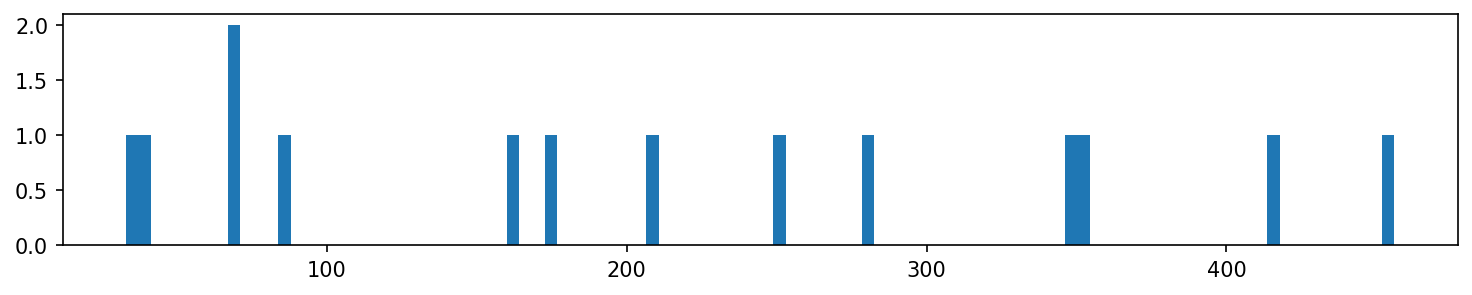

In [370]:
labeled_array, _ = label((filtered_frangi > 0), np.ones((3, 3, 3)))
plt.figure(figsize=(12, 2), dpi=150)
plt.hist([np.sum(labeled_array == i) for i in range(1,np.max(labeled_array)+1)], bins=100)
plt.show()

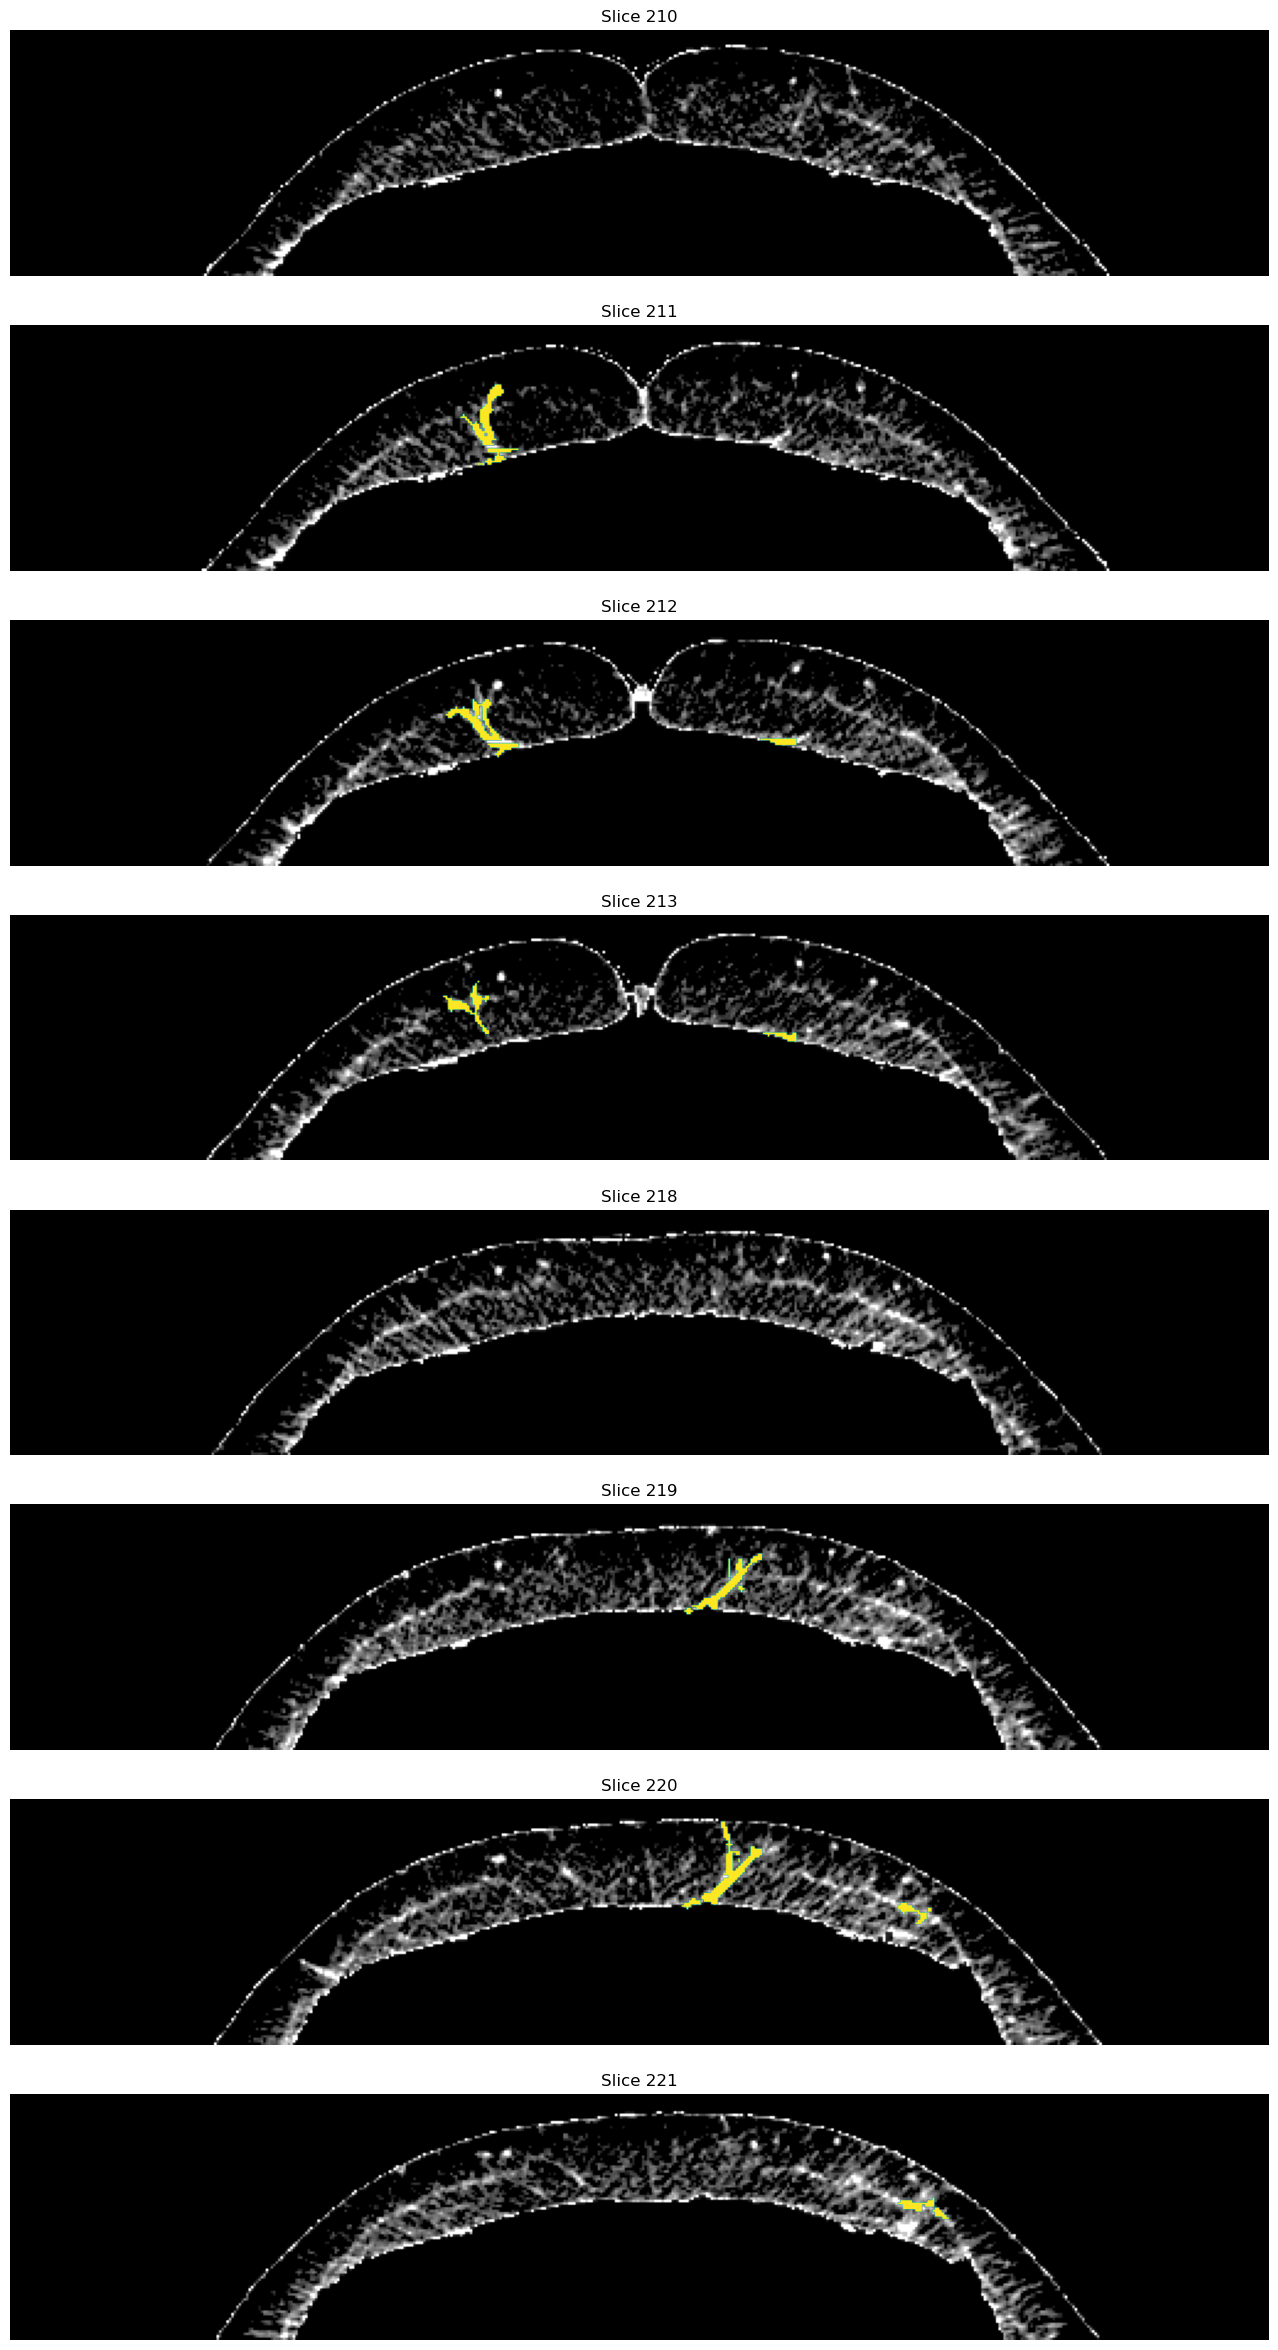

In [377]:
# filtered_frangi=grey_opening(filtered_frangi, size=(3,3,3))
temp = (filtered_frangi == 0)*yolo
fig,ax = plt.subplots(len(HP["slice_no"]),1, figsize=(100, 30), dpi=100)
for kiri,i in enumerate(HP["slice_no"]):#
    # plt.figure(figsize=(10, 5), dpi=200)
    ax[kiri].set_title(f"Slice {HP['slice_range'][0]+i}")
    ax[kiri].imshow(1-cropped_image[i], cmap="Grays")
    # plt.vlines(len(cropped_image[i,0])/2-8, 0, 300, color='blue', linestyles='dashed')
    # plt.vlines(len(cropped_image[i,0])/2+8, 0, 300, color='blue', linestyles='dashed')
    ax[kiri].imshow(filtered_frangi[i]> 0, alpha=(filtered_frangi[i] > 0).astype(float))
    # ax[kiri].imshow(temp[i], cmap='Greens', alpha=(temp[i] > 0).astype(float))
    ax[kiri].axis('off')
    # ax[i].show()

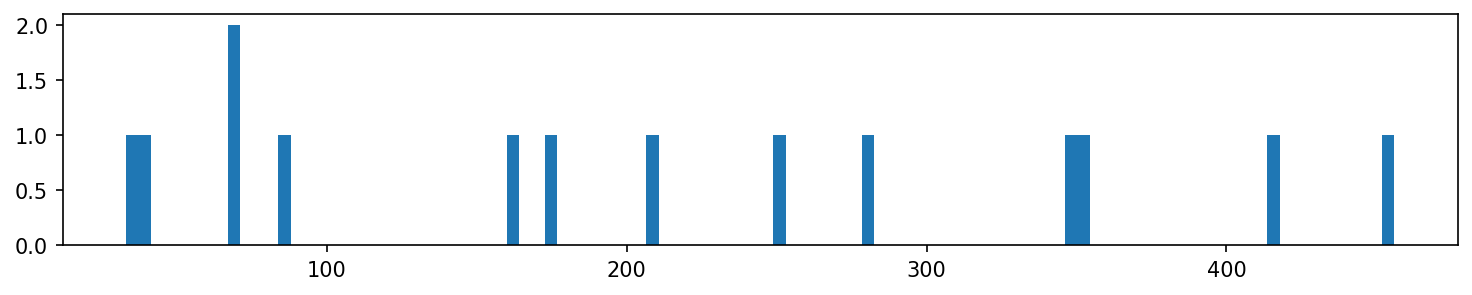

In [372]:
labeled_array, _ = label((filtered_frangi > 0), np.ones((3, 3, 3)))
plt.figure(figsize=(12, 2), dpi=150)
plt.hist([np.sum(labeled_array == i) for i in range(1,np.max(labeled_array)+1)], bins=100)
plt.show()